<a href="https://colab.research.google.com/github/MiguelAP6/IAAC/blob/feature%2Fmiguel-dataprep/LearningMiguel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Montar o Google Drive
from google.colab import drive
import sys
import os

drive.mount('/content/drive')

# Caminho para a pasta do vosso projeto no Drive (ajusta o nome se necessário)
project_path = '/content/drive/MyDrive/Projeto_Ciberseguranca'
sys.path.append(os.path.join(project_path, 'scripts'))

# Importar bibliotecas base de ML
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modelos do Módulo 6 (Supervised Learning)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

# Métricas de Avaliação
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

print("✓ Ambiente configurado e bibliotecas importadas com sucesso!")

Mounted at /content/drive
✓ Ambiente configurado e bibliotecas importadas com sucesso!


In [ ]:
import importlib
import prep_utils
import pandas as pd

importlib.reload(prep_utils)

data_path = '/content/drive/MyDrive/Projeto_Ciberseguranca/data/cybersecurity_intrusion_data.csv'
df = pd.read_csv(data_path)

# Adicionamos *extras para "apanhar" tudo o que a função devolver além dos 4 principais
X_train, X_test, y_train, y_test, *extras = prep_utils.preparar_dados_completo(df)

print(f"\nDados de Treino (após SMOTE): {X_train.shape}")
print(f"Dados de Teste: {X_test.shape}")

Preparação concluída! Variáveis selecionadas: ['login_attempts', 'session_duration', 'ip_reputation_score', 'failed_logins', 'unusual_time_access', 'fail_login_ratio', 'encryption_used_Desconhecido', 'browser_type_Edge', 'browser_type_Firefox', 'browser_type_Unknown']

Dados de Treino (após SMOTE): (8436, 10)
Dados de Teste: (1908, 10)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

# Dicionário com os algoritmos do Módulo 6
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "k-NN": KNeighborsClassifier(n_neighbors=5),
    "Naïve Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42)
}

results = []

print("--- A iniciar o treino e avaliação dos modelos do Módulo 6 ---")
print("Isto pode demorar uns segundos...\n")

for name, model in models.items():
    # 1. Treinar o modelo com os dados de treino (X_train, y_train)
    model.fit(X_train, y_train)

    # 2. Fazer previsões com os dados de teste (X_test) que o modelo nunca viu
    y_pred = model.predict(X_test)

    # 3. Calcular as métricas
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # 4. Guardar resultados
    results.append({
        "Modelo": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4)
    })
    print(f"✓ {name} treinado e avaliado com sucesso.")

# Converter os resultados num DataFrame e ordenar do melhor para o pior (baseado no F1-Score)
df_results = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)

print("\n=== Quadro Comparativo de Desempenho ===")
display(df_results)

--- A iniciar o treino e avaliação dos modelos do Módulo 6 ---
Isto pode demorar uns segundos...

✓ Logistic Regression treinado e avaliado com sucesso.
✓ Decision Tree treinado e avaliado com sucesso.
✓ k-NN treinado e avaliado com sucesso.
✓ Naïve Bayes treinado e avaliado com sucesso.
✓ Random Forest treinado e avaliado com sucesso.
✓ AdaBoost treinado e avaliado com sucesso.
✓ Gradient Boosting treinado e avaliado com sucesso.
✓ XGBoost treinado e avaliado com sucesso.

=== Quadro Comparativo de Desempenho ===


,Modelo,Accuracy,Precision,Recall,F1-Score
6,Gradient Boosting,0.8857,0.9984,0.7456,0.8537
7,XGBoost,0.8774,0.9613,0.7562,0.8465
4,Random Forest,0.8742,0.9554,0.7538,0.8427
5,AdaBoost,0.8643,1.0000,0.6964,0.8210
2,k-NN,0.8239,0.8507,0.7351,0.7887
1,Decision Tree,0.8050,0.7755,0.7937,0.7845
3,Naïve Bayes,0.8160,0.8959,0.6659,0.7640
0,Logistic Regression,0.7474,0.7101,0.7351,0.7224


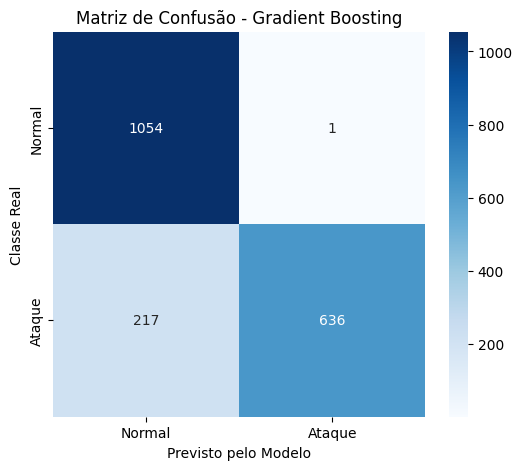


Relatório de Classificação Detalhado:
                precision    recall  f1-score   support

Tráfego Normal       0.83      1.00      0.91      1055
        Ataque       1.00      0.75      0.85       853

      accuracy                           0.89      1908
     macro avg       0.91      0.87      0.88      1908
  weighted avg       0.90      0.89      0.88      1908



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# Obter as previsões do modelo vencedor
best_model = models["Gradient Boosting"]
y_pred_best = best_model.predict(X_test)

# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Ataque'],
            yticklabels=['Normal', 'Ataque'])
plt.title('Matriz de Confusão - Gradient Boosting')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Classe Real')
plt.show()

# Relatório Detalhado
print("\nRelatório de Classificação Detalhado:")
print(classification_report(y_test, y_pred_best, target_names=['Tráfego Normal', 'Ataque']))

✓ SVM treinado com sucesso! Accuracy: 0.8726 | F1-Score: 0.8398


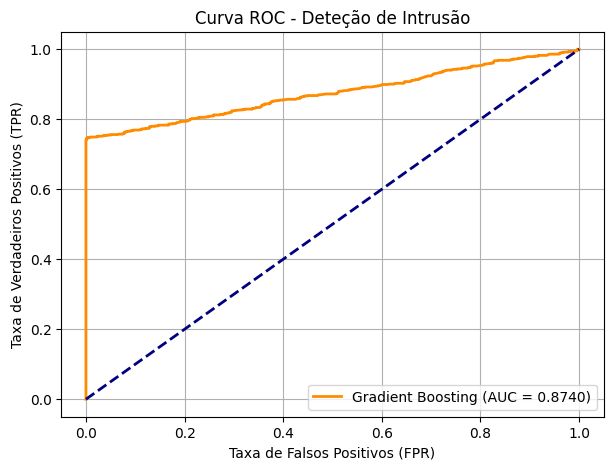

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Avaliar SVM para cumprir o requisito "M" de Support Vector Machines
svm_model = SVC(probability=True, random_state=42)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

print(f"✓ SVM treinado com sucesso! Accuracy: {accuracy_score(y_test, y_pred_svm):.4f} | F1-Score: {f1_score(y_test, y_pred_svm):.4f}")

# 2. Desenhar a Curva AUC-ROC do melhor modelo (Gradient Boosting)
y_probs_gb = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs_gb)
auc_score = roc_auc_score(y_test, y_probs_gb)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Gradient Boosting (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - Deteção de Intrusão')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

# Definir a grelha de hiperparâmetros
param_grid = {
    'n_estimators': [100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5]
}

# Configurar o GridSearch focando na otimização do Recall/F1
grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=3,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\n=== Melhores Hiperparâmetros Encontrados ===")
print(grid_search.best_params_)

# Avaliar modelo otimizado
best_gb_tuned = grid_search.best_estimator_
y_pred_tuned = best_gb_tuned.predict(X_test)
print(f"\nF1-Score após Tuning: {f1_score(y_test, y_pred_tuned):.4f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits

=== Melhores Hiperparâmetros Encontrados ===
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 150}

F1-Score após Tuning: 0.8537


In [ ]:
# Avaliar se o modelo sofre de Overfitting (memorização do treino)
train_f1 = f1_score(y_train, best_gb_tuned.predict(X_train))
test_f1 = f1_score(y_test, best_gb_tuned.predict(X_test))

print("=== Validação de Generalização (Módulo 7) ===")
print(f"F1-Score no Treino: {train_f1:.4f}")
print(f"F1-Score no Teste:  {test_f1:.4f}")

diff = abs(train_f1 - test_f1)
if diff <= 0.05:
    print(f"✓ Diferença de apenas {diff:.4f}: O modelo generaliza excelentemente sem overfitting.")
else:
    print(f"⚠️ Atenção: Existe um desvio de {diff:.4f} entre treino e teste.")

=== Validação de Generalização (Módulo 7) ===
F1-Score no Treino: 0.8751
F1-Score no Teste:  0.8537
✓ Diferença de apenas 0.0214: O modelo generaliza excelentemente sem overfitting.
